In [43]:
import pandas as pd
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv', encoding='latin-1')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [44]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [45]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicates: 0


In [46]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors= 'coerce')
print(df['TotalCharges'].isnull().sum())

11


In [47]:
print(df[df['TotalCharges'].isnull()][['customerID','tenure','TotalCharges']])

      customerID  tenure  TotalCharges
488   4472-LVYGI       0           NaN
753   3115-CZMZD       0           NaN
936   5709-LVOEQ       0           NaN
1082  4367-NUYAO       0           NaN
1340  1371-DWPAZ       0           NaN
3331  7644-OMVMY       0           NaN
3826  3213-VVOLG       0           NaN
4380  2520-SGTTA       0           NaN
5218  2923-ARZLG       0           NaN
6670  4075-WKNIU       0           NaN
6754  2775-SEFEE       0           NaN


In [48]:
df= df.dropna(subset=['TotalCharges'])
print(df.shape)

(7032, 21)


In [49]:
df = df.drop('customerID', axis=1)

In [50]:
df['Churn']=df['Churn'].map({'No': 0,'Yes':1})
print(df['Churn'].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


In [51]:
print(df.shape)
print(df['TotalCharges'].isnull().sum())

(7032, 20)
0


In [52]:
print(df['TotalCharges'].dtype)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors='coerce')
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isnull().sum())

float64
float64
0


In [53]:
df = df.dropna(subset=['TotalCharges'])
print(df.shape)
print(df['Churn'].value_counts())

(7032, 20)
Churn
0    5163
1    1869
Name: count, dtype: int64


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

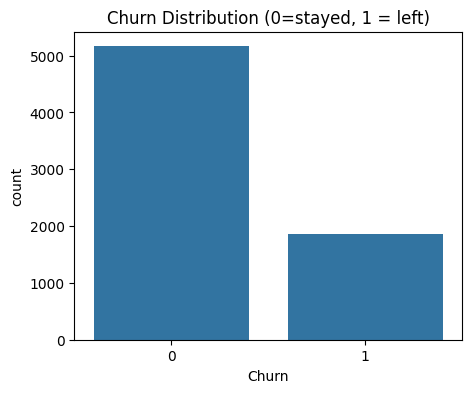

Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


In [55]:
plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data= df)
plt.title('Churn Distribution (0=stayed, 1 = left)')
plt.show()
print(df['Churn'].value_counts(normalize=True))

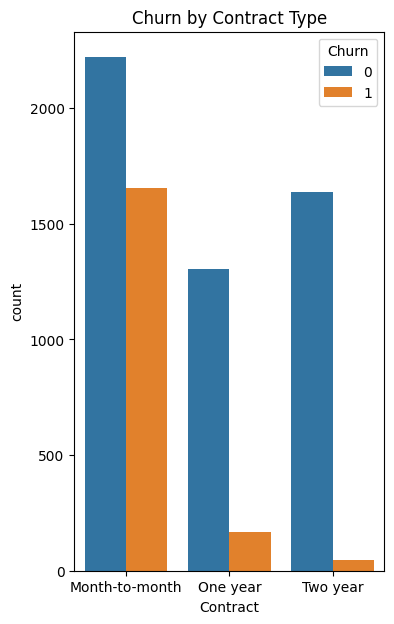

In [56]:
plt.figure(figsize=(4,7))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract Type')
plt.show()

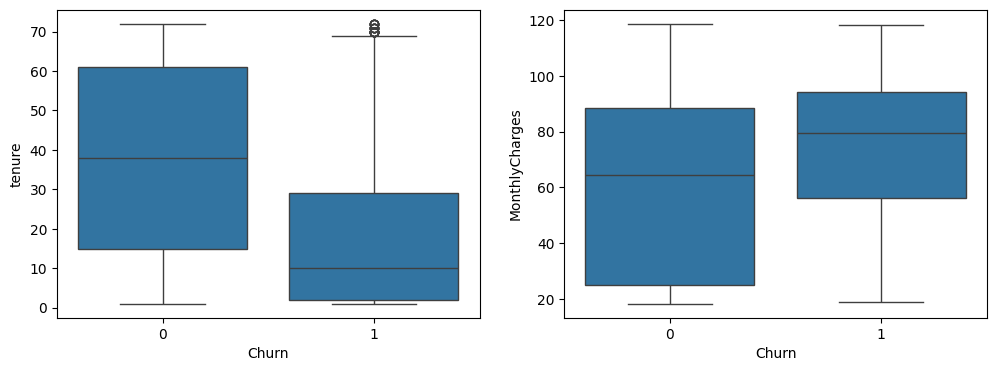

In [57]:
fig, axis = plt.subplots(1,2,figsize=(12,4))
sns.boxplot(x='Churn',y='tenure',data=df, ax=axis[0])
sns.boxplot(x='Churn',y='MonthlyCharges',data=df,ax=axis[1])
plt.show()


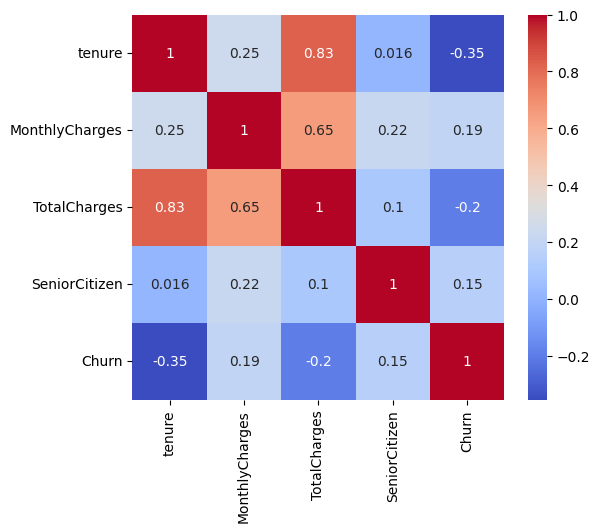

In [58]:
plt.figure(figsize=(6,5))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']].corr(),annot=True,cmap='coolwarm')
plt.show()

In [59]:
# Feature Engineering
df['tenure_group']= pd.cut(df['tenure'],bins=[0, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
df['avg_monthly_spend']=df['TotalCharges']/df['tenure']

In [60]:
print(df[['tenure','tenure_group','TotalCharges','avg_monthly_spend']].head())

   tenure tenure_group  TotalCharges  avg_monthly_spend
0       1         0-12         29.85          29.850000
1      34        25-48       1889.50          55.573529
2       2         0-12        108.15          54.075000
3      45        25-48       1840.75          40.905556
4       2         0-12        151.65          75.825000


In [61]:
from numpy import shape
x= df.drop('Churn',axis=1)
y = df['Churn']
print(x.shape,y.shape)

(7032, 21) (7032,)


In [62]:
cat_cols= x.select_dtypes(include=['object','category']).columns.tolist()
num_cols= x.select_dtypes(include=['int64','float64']).columns.tolist()
print('Catogories:', cat_cols )
print('Numeric:',num_cols)

Catogories: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']
Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend']


In [63]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(x,y, test_size=0.2,random_state=42,stratify=y)
print(x_train.shape,x_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))



(5625, 21) (1407, 21)
Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64
Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocesser = ColumnTransformer([
    ('num',StandardScaler(),num_cols),
    ('cat',OneHotEncoder(handle_unknown='ignore'),cat_cols)
     ])

log_model = Pipeline([
    ('prep', preprocesser),
    ('clf',LogisticRegression(max_iter=1000))
])

log_model.fit(x_train,y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'avg_monthly_spend']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group'])])),
                ('clf', LogisticRegression(max_iter=1000))])

In [65]:
from sklearn.metrics import classification_report,confusion_matrix, roc_auc_score
y_pred = log_model.predict(x_test)
y_prob = log_model.predict_proba(x_test[:1])
print('Train accuracy:', log_model.score(x_train,y_train))
print('Test accuracy:', log_model.score(x_test,y_test))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Train accuracy: 0.8085333333333333
Test accuracy: 0.7924662402274343
[[919 114]
 [178 196]]
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



In [66]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score,recall_score

models = {
    'Logistics Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest':RandomForestClassifier(random_state=42)

}

results=[]
for name, clf in models.items():
  pipe = Pipeline([('prep', preprocesser),('clf',clf)])
  pipe.fit(x_train,y_train)
  results.append({
      'Model':name,
      'Test acc':pipe.score(x_test,y_test),
      'Train Acc': pipe.score(x_train,y_train),
      'Recall(churn)': recall_score(y_test,pipe.predict(x_test)),
      'F1(churn)': f1_score(y_test,pipe.predict(x_test)),
      'ROC-AUC': roc_auc_score(y_test,pipe.predict_proba(x_test)[:, 1])

  })

results_df = pd.DataFrame(results).round(3)
print(results_df)


                  Model  Test acc  Train Acc  Recall(churn)  F1(churn)  \
0  Logistics Regression     0.792      0.809          0.524      0.573   
1         Decision Tree     0.721      0.999          0.481      0.478   
2         Random Forest     0.786      0.999          0.503      0.555   

   ROC-AUC  
0    0.835  
1    0.645  
2    0.817  


In [67]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name,clf in models.items():
  pipe=Pipeline([('prep',preprocesser),('clf',clf)])
  scores = cross_val_score(pipe,x,y,cv=cv,scoring='roc_auc')
  print(f"{name}: Means ROC-AUC = {scores.mean():.3f} (+/-{scores.std():.3f})")

Logistics Regression: Means ROC-AUC = 0.846 (+/-0.003)
Decision Tree: Means ROC-AUC = 0.651 (+/-0.008)
Random Forest: Means ROC-AUC = 0.823 (+/-0.003)


In [68]:
from sklearn.metrics import precision_score
balanced_models = {
    'LogReg (balanced)': LogisticRegression(max_iter=1000,class_weight='balanced'),
    'Random Forest (balanced)':RandomForestClassifier(random_state=42, class_weight='balanced')
}
for name,clf in balanced_models.items():
  pipe = Pipeline([('prep',preprocesser),('clf',clf)])
  pipe.fit(x_train,y_train)
  pred = pipe.predict(x_test)
  print(name)
  print(
        "Recall:",round(recall_score(y_test,pred),3),
        "|precision:", round(precision_score(y_test,pred),3),
        "|F1:", round(f1_score(y_test,pred),3),
        "|ROC-AUC:", round(
    roc_auc_score(y_test, pipe.predict_proba(x_test)[:, 1]), 3
)

    )

LogReg (balanced)
Recall: 0.791 |precision: 0.486 |F1: 0.602 |ROC-AUC: 0.834
Random Forest (balanced)
Recall: 0.487 |precision: 0.625 |F1: 0.547 |ROC-AUC: 0.812


In [69]:
from sklearn.model_selection import GridSearchCV
pipe = Pipeline([
    ('prep',preprocesser),
    ('clf',LogisticRegression(max_iter=1000,class_weight='balanced'))
])

parm_grid = {
    'clf__C':[0.01,0.1,1,10],
    'clf__penalty':['l1','l2'],
    'clf__solver':['liblinear']
}
grid = GridSearchCV(pipe,parm_grid,cv=5,scoring='f1',n_jobs=-1)
grid.fit(x_train,y_train)

print("Best Params :", grid.best_params_)
print("Best CV F1 :",grid.best_score_,3 )

best_model = grid.best_estimator_
pred = best_model.predict(x_test)
print("Test Recall: ",round(recall_score(y_test,pred),3))
print("Test Precision: ", round(precision_score(y_test,pred),3))
print("Test F1: ",round(f1_score(y_test,pred),3))
print("ROC-AUC: ",round(roc_auc_score(y_test, best_model.predict_proba(x_test)[:,1]),3))


Best Params : {'clf__C': 0.1, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
Best CV F1 : 0.6332994288418373 3
Test Recall:  0.789
Test Precision:  0.495
Test F1:  0.608
ROC-AUC:  0.835


In [70]:
feature_names = best_model.named_steps['prep'].get_feature_names_out()
coefs = best_model.named_steps['clf'].coef_[0]
importance = pd.DataFrame({'feature':feature_names,'coefficient':coefs})
importance['abs_coef'] = importance['coefficient'].abs()
importance = importance.sort_values('abs_coef',ascending= False)
print(importance.head(10))


                                feature  coefficient  abs_coef
37         cat__Contract_Month-to-month     0.782841  0.782841
1                           num__tenure    -0.728742  0.728742
39               cat__Contract_Two year    -0.674483  0.674483
12                cat__PhoneService_Yes    -0.633567  0.633567
2                   num__MonthlyCharges     0.437095  0.437095
47              cat__tenure_group_13-24    -0.411546  0.411546
21              cat__OnlineSecurity_Yes    -0.349449  0.349449
44  cat__PaymentMethod_Electronic check     0.327766  0.327766
48              cat__tenure_group_25-48    -0.317925  0.317925
4                num__avg_monthly_spend     0.256216  0.256216


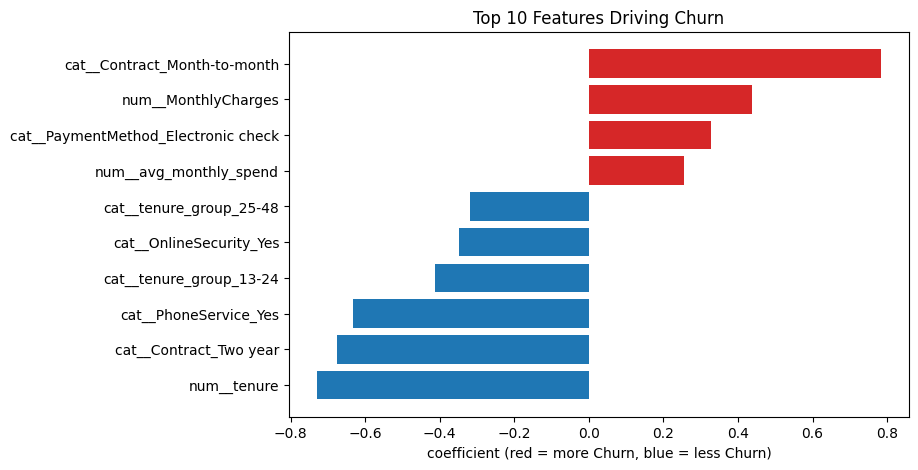

In [71]:
top = importance.head(10).sort_values('coefficient')
colors = ['tab:red' if c > 0 else 'tab:blue' for c in top['coefficient']]
plt.figure(figsize=(8,5))
plt.barh(top['feature'],top['coefficient'],color=colors)
plt.title("Top 10 Features Driving Churn")
plt.xlabel('coefficient (red = more Churn, blue = less Churn)')
plt.savefig('ferature_importance.png',dpi=150,bbox_inches= 'tight')
plt.show()



In [72]:
import joblib, sklearn
from google.colab import files

joblib.dump(best_model, 'churn_model.joblib')
files.download('churn_model.joblib')
print("scikit-learn version:", sklearn.__version__)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

scikit-learn version: 1.6.1


In [73]:
customer = {
    'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No',
    'tenure': 3, 'PhoneService': 'Yes', 'MultipleLines': 'No',
    'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No',
    'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'No',
    'StreamingMovies': 'No', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check', 'MonthlyCharges': 80.0, 'TotalCharges': 240.0
}

new_df = pd.DataFrame([customer])
new_df['tenure_group'] = pd.cut(new_df['tenure'], bins=[0, 12, 24, 48, 72],
                                labels=['0-12', '13-24', '25-48', '49-72'])
new_df['avg_monthly_spend'] = new_df['TotalCharges'] / new_df['tenure']

print(f"Churn probability: {best_model.predict_proba(new_df)[0][1]:.1%}")

Churn probability: 88.3%
